### 1. Importação de Bíbliotecas

In [19]:
import simpy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Denifição de semente fixa, para que a simulação seja reprodutível em outras execuções.
np.random.seed(42)

### 2. Modelagem e Processamento Matemático

In [20]:
class SistemaBicicletas:
    def __init__(self, env, cap_origem=20, init_origem=15, cap_destino=20, init_destino=5):
        self.env = env
        # Containers gerenciam o estoque. capacity = Vagas totais. init = Bikes atuais.
        self.estacao_origem = simpy.Container(env, capacity=cap_origem, init=init_origem)
        self.estacao_destino = simpy.Container(env, capacity=cap_destino, init=init_destino)
        
        # Variáveis para coleta de métricas
        self.registro_historico = []
        self.desistencias_origem = 0
        self.desistencias_destino = 0
        
        # Inicia o processo que fotografa o estado do sistema minuto a minuto
        env.process(self.monitorar_estacoes())

    def monitorar_estacoes(self):
        while True:
            self.registro_historico.append({
                'Minuto': self.env.now,
                'Bikes_Origem': self.estacao_origem.level,
                'Bikes_Destino': self.estacao_destino.level,
                'Vagas_Destino': self.estacao_destino.capacity - self.estacao_destino.level
            })
            yield self.env.timeout(1)

def usuario_viagem(env, nome, sistema):
    # 1. TENTATIVA DE RETIRADA (Fila na Origem)

    # O usuário pede 1 bicicleta. O operador '|' cria uma condição de corrida (Timeout).
    req_bike = sistema.estacao_origem.get(1)
    resultado_retirada = yield req_bike | env.timeout(5) # Espera no máximo 5 minutos
    
    if req_bike not in resultado_retirada:
        sistema.desistencias_origem += 1
        return # Encerra o processo do usuário (Desistência)

    # 2. TEMPO DE SERVIÇO (Duração da Viagem)

    # Modelado com distribuição Exponencial (viagens curtas são mais comuns)
    tempo_viagem = np.random.exponential(scale=15) # Média de 15 minutos
    yield env.timeout(tempo_viagem)
    
    # 3. TENTATIVA DE DEVOLUÇÃO (Fila no Destino)

    # O usuário tenta devolver (put) 1 bicicleta no destino.
    req_vaga = sistema.estacao_destino.put(1)
    resultado_devolucao = yield req_vaga | env.timeout(10) # Espera no máximo 10 minutos por uma vaga
    
    if req_vaga not in resultado_devolucao:
        sistema.desistencias_destino += 1
        # Na prática, o usuário procuraria outra estação. Aqui registramos como falha.

def gerador_usuarios(env, sistema, taxa_chegada):
    i = 0
    while True:
        # Chegadas seguem um Processo de Poisson (intervalos exponenciais)
        intervalo_chegada = np.random.exponential(scale=taxa_chegada)
        yield env.timeout(intervalo_chegada)
        i += 1
        env.process(usuario_viagem(env, f'User_{i}', sistema))

env = simpy.Environment()
sistema_base = SistemaBicicletas(env)

# Taxa de chegada: 1 usuário a cada 3 minutos (média)
env.process(gerador_usuarios(env, sistema_base, taxa_chegada=3))

# Simular 12 horas de operação (720 minutos)
env.run(until=720)

# Estruturação dos dados coletados
df_resultados = pd.DataFrame(sistema_base.registro_historico)
print("Resultados do caso Base:")
print(f"Total de Desistências por falta de bicicleta (Origem): {sistema_base.desistencias_origem}")
print(f"Total de Desistências por falta de vaga (Destino): {sistema_base.desistencias_destino}")

Resultados do caso Base:
Total de Desistências por falta de bicicleta (Origem): 226
Total de Desistências por falta de vaga (Destino): 0


### 3. Visualização dos Dados

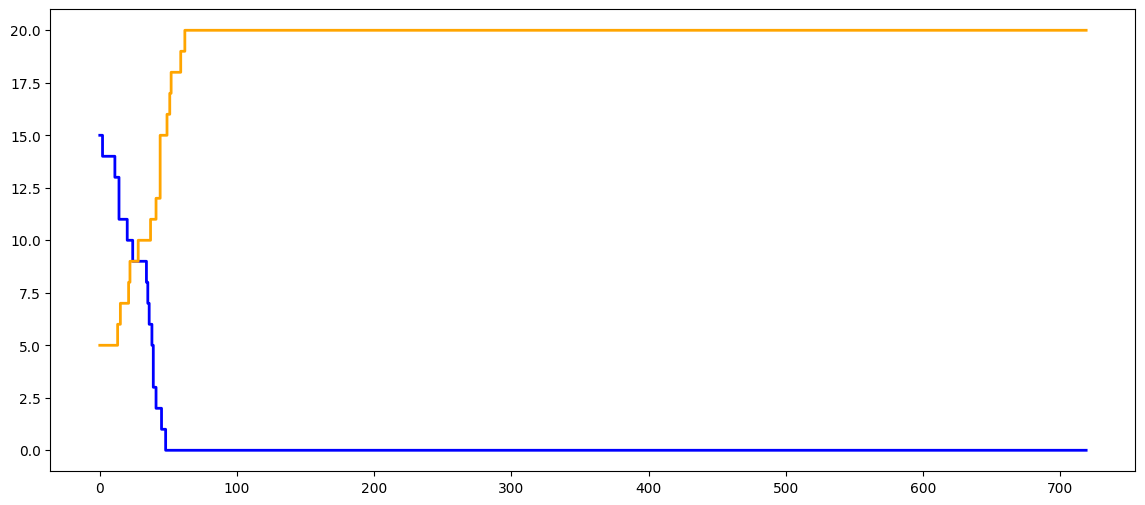

In [21]:
plt.figure(figsize=(14, 6))

# Gráfico: Disponibilidade de Bicicletas ao Longo do Tempo
# Utilizamos plt.step em vez de plt.plot para refletir a natureza discreta do SimPy
plt.step(df_resultados['Minuto'], df_resultados['Bikes_Origem'], 
         label='Bikes Disponíveis (Origem)', where='post', color='blue', linewidth=2)
plt.step(df_resultados['Minuto'], df_resultados['Bikes_Destino'], 
         label='Bikes Disponíveis (Destino)', where='post', color='orange', linewidth=2)

plt.show()